<a href="https://colab.research.google.com/github/secrabdou/Customer-Segmentation/blob/main/Dog_cat_classifier_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader , random_split
from torchvision.datasets import OxfordIIITPet
from torchvision import models , transforms
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path

# --- Paths: work on Colab (checkpoints go to Google Drive) and locally ---
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

DATA_DIR = "data" if ON_COLAB else "../data"  # dataset stays on local disk, re-downloaded each Colab session
OUTPUT_DIR = Path("/content/drive/MyDrive/pet-project/outputs") if ON_COLAB else Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # torch.save does not create missing folders
MODEL_PATH = OUTPUT_DIR / "resnet34_pet_breeds.pth"
IMAGE_SIZE = 224
BATCH_SIZE = 32
FREEZE_EPOCHS = 3
UNFREEZE_EPOCHS = 8
SEED = 42
VAL_FRACTION = 0.2

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device : " , device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device :  cuda


In [4]:
train_transforms = transforms.Compose([
    transforms.RandomRotation(5),
    transforms.RandomResizedCrop((IMAGE_SIZE, IMAGE_SIZE), scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=.2, contrast=.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
eval_transforms= transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

full_dataset = OxfordIIITPet(
    root=DATA_DIR,
    split='trainval',
    target_types='category',
    download=True,
    transform=train_transforms,
)

class_names = full_dataset.classes
num_classes = len(class_names)
print(f"Total images: {len(full_dataset)}")
print(f"Number of breeds: {num_classes}")
print("Sample breeds:", class_names[:5])



100%|██████████| 792M/792M [00:05<00:00, 137MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 105MB/s] 


Total images: 3680
Number of breeds: 37
Sample breeds: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


Images per breed -- min: 93, max: 100, mean: 99.5


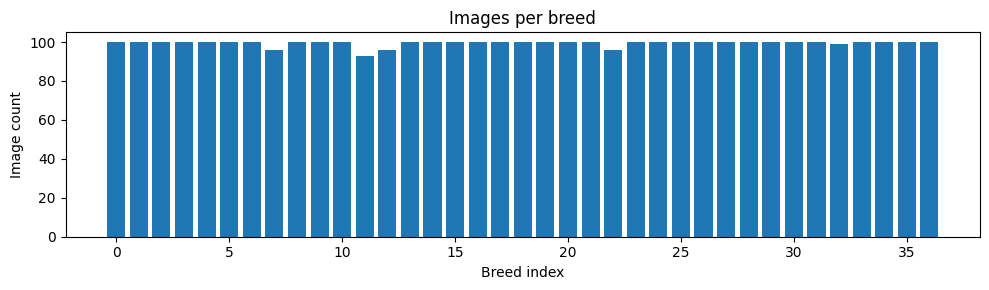

In [5]:
labels = full_dataset._labels  # already in memory; looping over dataset[i] would decode every image
counts = np.bincount(labels)
print(f"Images per breed -- min: {counts.min()}, max: {counts.max()}, mean: {counts.mean():.1f}")

plt.figure(figsize=(10, 3))
plt.bar(range(num_classes), counts)
plt.xlabel("Breed index")
plt.ylabel("Image count")
plt.title("Images per breed")
plt.tight_layout()
plt.show()


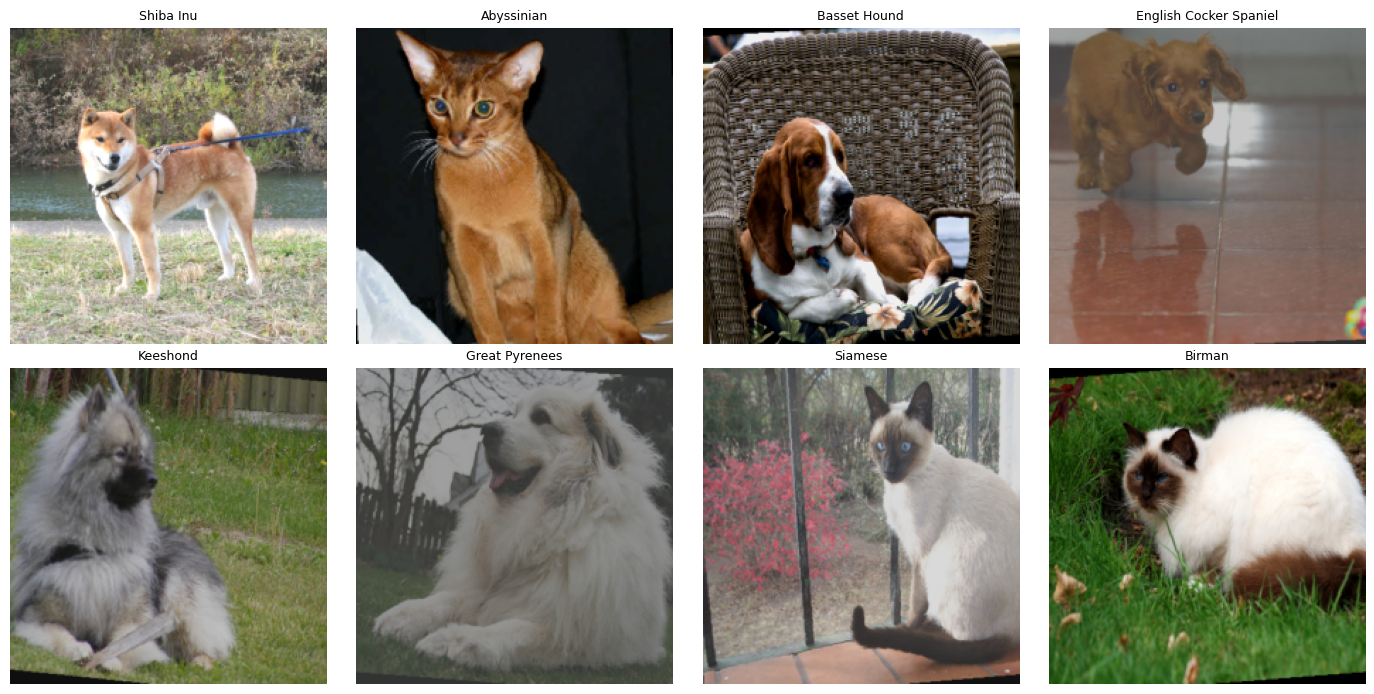

In [6]:
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.numpy().transpose((1,2,0))
    return np.clip(std * img + mean , 0 , 1)

fig , axes = plt.subplots(2,4,figsize = (14 ,7))
for ax in axes.flat :
    idx = np.random.randint(len(full_dataset))
    img , label = full_dataset[idx]
    ax.imshow(denormalize(img))
    ax.set_title(class_names[label] , fontsize = 9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
val_size = int(len(full_dataset) * VAL_FRACTION)
train_size = len(full_dataset) - val_size
generator = torch.Generator().manual_seed(SEED)
train_dataset , val_dataset = random_split(full_dataset , [train_size , val_size] , generator=generator)

val_dataset.dataset =  OxfordIIITPet(
    root = DATA_DIR , split ='trainval' , target_types='category' , download=False ,
    transform=eval_transforms
)

train_loader = DataLoader(train_dataset , batch_size= BATCH_SIZE, shuffle=True , num_workers=2)
val_loader = DataLoader(val_dataset , batch_size= BATCH_SIZE, shuffle=False , num_workers=2)

print(f"train : {len(train_dataset)} images | eval : {len(val_dataset)} images ")

train : 2944 images | eval : 736 images 


In [8]:
def build_model(num_classes):
    model = models.resnet34(weights =models.ResNet34_Weights.DEFAULT)
    for param in model.parameters():
        param.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features , num_classes)
    return model.to(device)

def run_epoch(model , loader , criterion , optimizer =None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss , correct , total = 0.0 , 0, 0
    torch.set_grad_enabled(is_train)
    for inputs , labels in loader :
        inputs , labels = inputs.to(device) , labels.to(device)
        if is_train:
            optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        if is_train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * inputs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += inputs.size(0)
    return total_loss / total, correct / total

model = build_model(num_classes)
criterion = nn.CrossEntropyLoss()




Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 176MB/s]


In [9]:
# ---- Stage A: train the new head only ----
optimizer = optim.AdamW(model.fc.parameters(), lr=1e-3 , weight_decay=1e-2)
print(f"--- Stage A: head only ({FREEZE_EPOCHS} epochs) ---")
for epoch in range(1, FREEZE_EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion)
    print(f"Epoch {epoch} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.2%} "
          f"| Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2%}")


--- Stage A: head only (3 epochs) ---
Epoch 1 | Train Loss: 2.0868, Acc: 53.63% | Val Loss: 0.9637, Val Acc: 83.70%
Epoch 2 | Train Loss: 0.7544, Acc: 85.53% | Val Loss: 0.5973, Val Acc: 86.41%
Epoch 3 | Train Loss: 0.5141, Acc: 89.03% | Val Loss: 0.4727, Val Acc: 87.91%


In [10]:
# ---- Stage B: unfreeze everything, fine-tune fully ----
for param in model.parameters():
    param.requires_grad = True

optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)

best_val_acc = 0.0

for epoch in range(1, UNFREEZE_EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion)
    print(f"Epoch {epoch} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.2%} "
          f"| Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2%}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), MODEL_PATH)
        print(f"  -> new best (val acc {val_acc:.2%}), checkpoint saved")

print(f"\nBest validation accuracy: {best_val_acc:.2%}")

Epoch 1 | Train Loss: 0.3816, Acc: 88.52% | Val Loss: 0.3475, Val Acc: 88.59%
  -> new best (val acc 88.59%), checkpoint saved
Epoch 2 | Train Loss: 0.1322, Acc: 96.88% | Val Loss: 0.2987, Val Acc: 89.27%
  -> new best (val acc 89.27%), checkpoint saved
Epoch 3 | Train Loss: 0.0855, Acc: 97.93% | Val Loss: 0.2814, Val Acc: 89.95%
  -> new best (val acc 89.95%), checkpoint saved
Epoch 4 | Train Loss: 0.0678, Acc: 98.37% | Val Loss: 0.2950, Val Acc: 89.67%
Epoch 5 | Train Loss: 0.0567, Acc: 98.57% | Val Loss: 0.3210, Val Acc: 88.45%
Epoch 6 | Train Loss: 0.0429, Acc: 99.39% | Val Loss: 0.3159, Val Acc: 90.35%
  -> new best (val acc 90.35%), checkpoint saved
Epoch 7 | Train Loss: 0.0279, Acc: 99.63% | Val Loss: 0.2760, Val Acc: 91.71%
  -> new best (val acc 91.71%), checkpoint saved
Epoch 8 | Train Loss: 0.0280, Acc: 99.42% | Val Loss: 0.3256, Val Acc: 90.22%

Best validation accuracy: 91.71%


In [11]:
from torchvision.models.segmentation import deeplabv3_resnet50
from torchvision.models import ResNet50_Weights
import torchvision.transforms.functional as TF
import random

SEG_MODEL_PATH = OUTPUT_DIR / "deeplabv3_pet_segmentation.pth"
NUM_SEG_CLASSES = 2          # pet, background -- boundary is ignored, not a 3rd class
BOUNDARY_IGNORE_INDEX = 2    # raw trimap value after remap, passed to CrossEntropyLoss
SEG_BATCH_SIZE = 8           # segmentation is heavier per-image than classification
SEG_FREEZE_EPOCHS = 3
SEG_UNFREEZE_EPOCHS = 10

In [12]:
class PetSegmentationDataset(torch.utils.data.Dataset):
    def __init__(self, root, split, img_size=IMAGE_SIZE, train=True):
        self.base = OxfordIIITPet(root=root, split=split, target_types="segmentation", download=False)
        self.img_size = img_size
        self.train = train

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        image, mask = self.base[idx]

        image = TF.resize(image, [self.img_size, self.img_size], interpolation=TF.InterpolationMode.BILINEAR)
        mask = TF.resize(mask, [self.img_size, self.img_size], interpolation=TF.InterpolationMode.NEAREST)

        if self.train and random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        image = TF.to_tensor(image)
        image = TF.normalize(image, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

        mask = torch.as_tensor(np.array(mask), dtype=torch.long) - 1  # {1,2,3} -> {0,1,2}

        return image, mask


seg_train_dataset = PetSegmentationDataset(DATA_DIR, split="trainval", train=True)
seg_val_dataset = PetSegmentationDataset(DATA_DIR, split="test", train=False)

seg_train_loader = DataLoader(seg_train_dataset, batch_size=SEG_BATCH_SIZE, shuffle=True, num_workers=2 , pin_memory=True)
seg_val_loader = DataLoader(seg_val_dataset, batch_size=SEG_BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Seg train: {len(seg_train_dataset)} images | Seg val: {len(seg_val_dataset)} images")



Seg train: 3680 images | Seg val: 3669 images


Image shape: (3, 224, 224) | Mask shape: (224, 224)
Mask unique values (should be within {0,1,2}): [0, 1, 2]


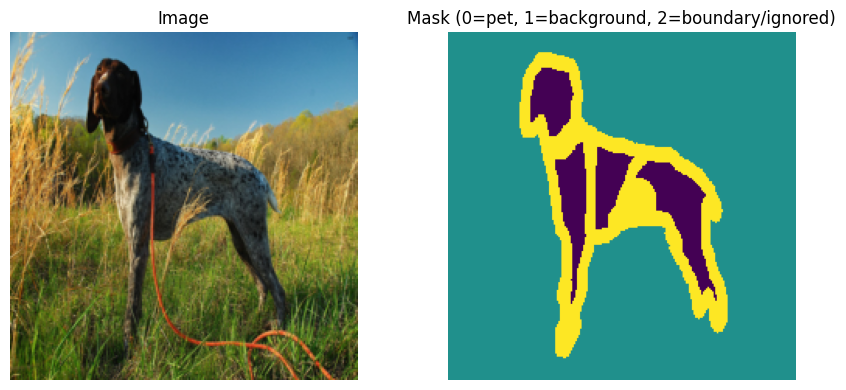

In [13]:
img_t, mask_t = seg_train_dataset[random.randint(0, len(seg_train_dataset) - 1)]
print(f"Image shape: {tuple(img_t.shape)} | Mask shape: {tuple(mask_t.shape)}")
print(f"Mask unique values (should be within {{0,1,2}}): {torch.unique(mask_t).tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(denormalize(img_t))
axes[0].set_title("Image")
axes[0].axis("off")
axes[1].imshow(mask_t.numpy(), cmap="viridis", vmin=0, vmax=2)
axes[1].set_title("Mask (0=pet, 1=background, 2=boundary/ignored)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [14]:
from torchmetrics.classification import MulticlassJaccardIndex

def build_seg_model(num_classes):
    model = deeplabv3_resnet50(
        weights=None,
        weights_backbone=ResNet50_Weights.DEFAULT,
        num_classes=num_classes,
        aux_loss=False,
    )
    for param in model.backbone.parameters():
        param.requires_grad = False
    return model.to(device)

def run_epoch_seg(model , loader , criterion , optimizer = None):

    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    iou_metric = MulticlassJaccardIndex(
        num_classes=NUM_SEG_CLASSES,
        ignore_index=BOUNDARY_IGNORE_INDEX,
        average="macro",
    ).to(device)
    total_loss , n_batches = 0.0 ,0

    torch.set_grad_enabled(is_train)
    for images , masks in loader:
        images, masks = images.to(device) , masks.to(device)

        if(is_train):
            optimizer.zero_grad()

        logits = model(images)["out"]
        loss = criterion(logits , masks)

        if(is_train):
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        iou_metric.update(logits.argmax(dim = 1 ) , masks)
        n_batches += 1

    return total_loss / n_batches , iou_metric.compute().item()

seg_model = build_seg_model(NUM_SEG_CLASSES)
seg_criterion = torch.nn.CrossEntropyLoss(ignore_index=BOUNDARY_IGNORE_INDEX)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 172MB/s]


In [15]:
# ---- Stage A: train the segmentation head only, backbone frozen ----
seg_optimizer = optim.AdamW(seg_model.classifier.parameters(), lr=1e-3, weight_decay=1e-2)
print(f"--- Stage A: head only ({SEG_FREEZE_EPOCHS} epochs) ---")
for epoch in range(1, SEG_FREEZE_EPOCHS + 1):
    train_loss, train_iou = run_epoch_seg(seg_model, seg_train_loader, seg_criterion, seg_optimizer)
    val_loss, val_iou = run_epoch_seg(seg_model, seg_val_loader, seg_criterion)
    print(f"Epoch {epoch} | Train Loss: {train_loss:.4f}, IoU: {train_iou:.4f} "
          f"| Val Loss: {val_loss:.4f}, Val IoU: {val_iou:.4f}")

--- Stage A: head only (3 epochs) ---
Epoch 1 | Train Loss: 0.1380, IoU: 0.8902 | Val Loss: 0.1106, Val IoU: 0.9156
Epoch 2 | Train Loss: 0.1014, IoU: 0.9197 | Val Loss: 0.0863, Val IoU: 0.9350
Epoch 3 | Train Loss: 0.0905, IoU: 0.9286 | Val Loss: 0.0841, Val IoU: 0.9374


In [16]:
# ---- Stage B: unfreeze the backbone, fine-tune everything ----
for param in seg_model.parameters():
    param.requires_grad = True

seg_optimizer = optim.AdamW(seg_model.parameters(), lr=1e-4, weight_decay=1e-2)
best_val_iou = 0.0

print(f"--- Stage B: full fine-tuning ({SEG_UNFREEZE_EPOCHS} epochs) ---")
for epoch in range(1, SEG_UNFREEZE_EPOCHS + 1):
    train_loss, train_iou = run_epoch_seg(seg_model, seg_train_loader, seg_criterion, seg_optimizer)
    val_loss, val_iou = run_epoch_seg(seg_model, seg_val_loader, seg_criterion)
    print(f"Epoch {epoch} | Train Loss: {train_loss:.4f}, IoU: {train_iou:.4f} "
          f"| Val Loss: {val_loss:.4f}, Val IoU: {val_iou:.4f}")

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(seg_model.state_dict(), SEG_MODEL_PATH)
        print(f"  -> new best (val IoU {val_iou:.4f}), checkpoint saved")

print(f"\nBest validation IoU: {best_val_iou:.4f}")


--- Stage B: full fine-tuning (10 epochs) ---
Epoch 1 | Train Loss: 0.0474, IoU: 0.9642 | Val Loss: 0.0462, Val IoU: 0.9708
  -> new best (val IoU 0.9708), checkpoint saved
Epoch 2 | Train Loss: 0.0261, IoU: 0.9805 | Val Loss: 0.0426, Val IoU: 0.9733
  -> new best (val IoU 0.9733), checkpoint saved
Epoch 3 | Train Loss: 0.0170, IoU: 0.9872 | Val Loss: 0.0432, Val IoU: 0.9764
  -> new best (val IoU 0.9764), checkpoint saved
Epoch 4 | Train Loss: 0.0139, IoU: 0.9894 | Val Loss: 0.0471, Val IoU: 0.9742
Epoch 5 | Train Loss: 0.0110, IoU: 0.9918 | Val Loss: 0.0458, Val IoU: 0.9743
Epoch 6 | Train Loss: 0.0101, IoU: 0.9924 | Val Loss: 0.0439, Val IoU: 0.9785
  -> new best (val IoU 0.9785), checkpoint saved
Epoch 7 | Train Loss: 0.0077, IoU: 0.9942 | Val Loss: 0.0468, Val IoU: 0.9779
Epoch 8 | Train Loss: 0.0057, IoU: 0.9957 | Val Loss: 0.0455, Val IoU: 0.9799
  -> new best (val IoU 0.9799), checkpoint saved
Epoch 9 | Train Loss: 0.0053, IoU: 0.9961 | Val Loss: 0.0472, Val IoU: 0.9787
Epoch 1

In [18]:
# classification
model = build_model(num_classes)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

# segmentation
seg_model = build_seg_model(NUM_SEG_CLASSES)
seg_model.load_state_dict(torch.load(SEG_MODEL_PATH, map_location=device))
seg_model.eval()

DeepLabV3(
  (backbone): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Se

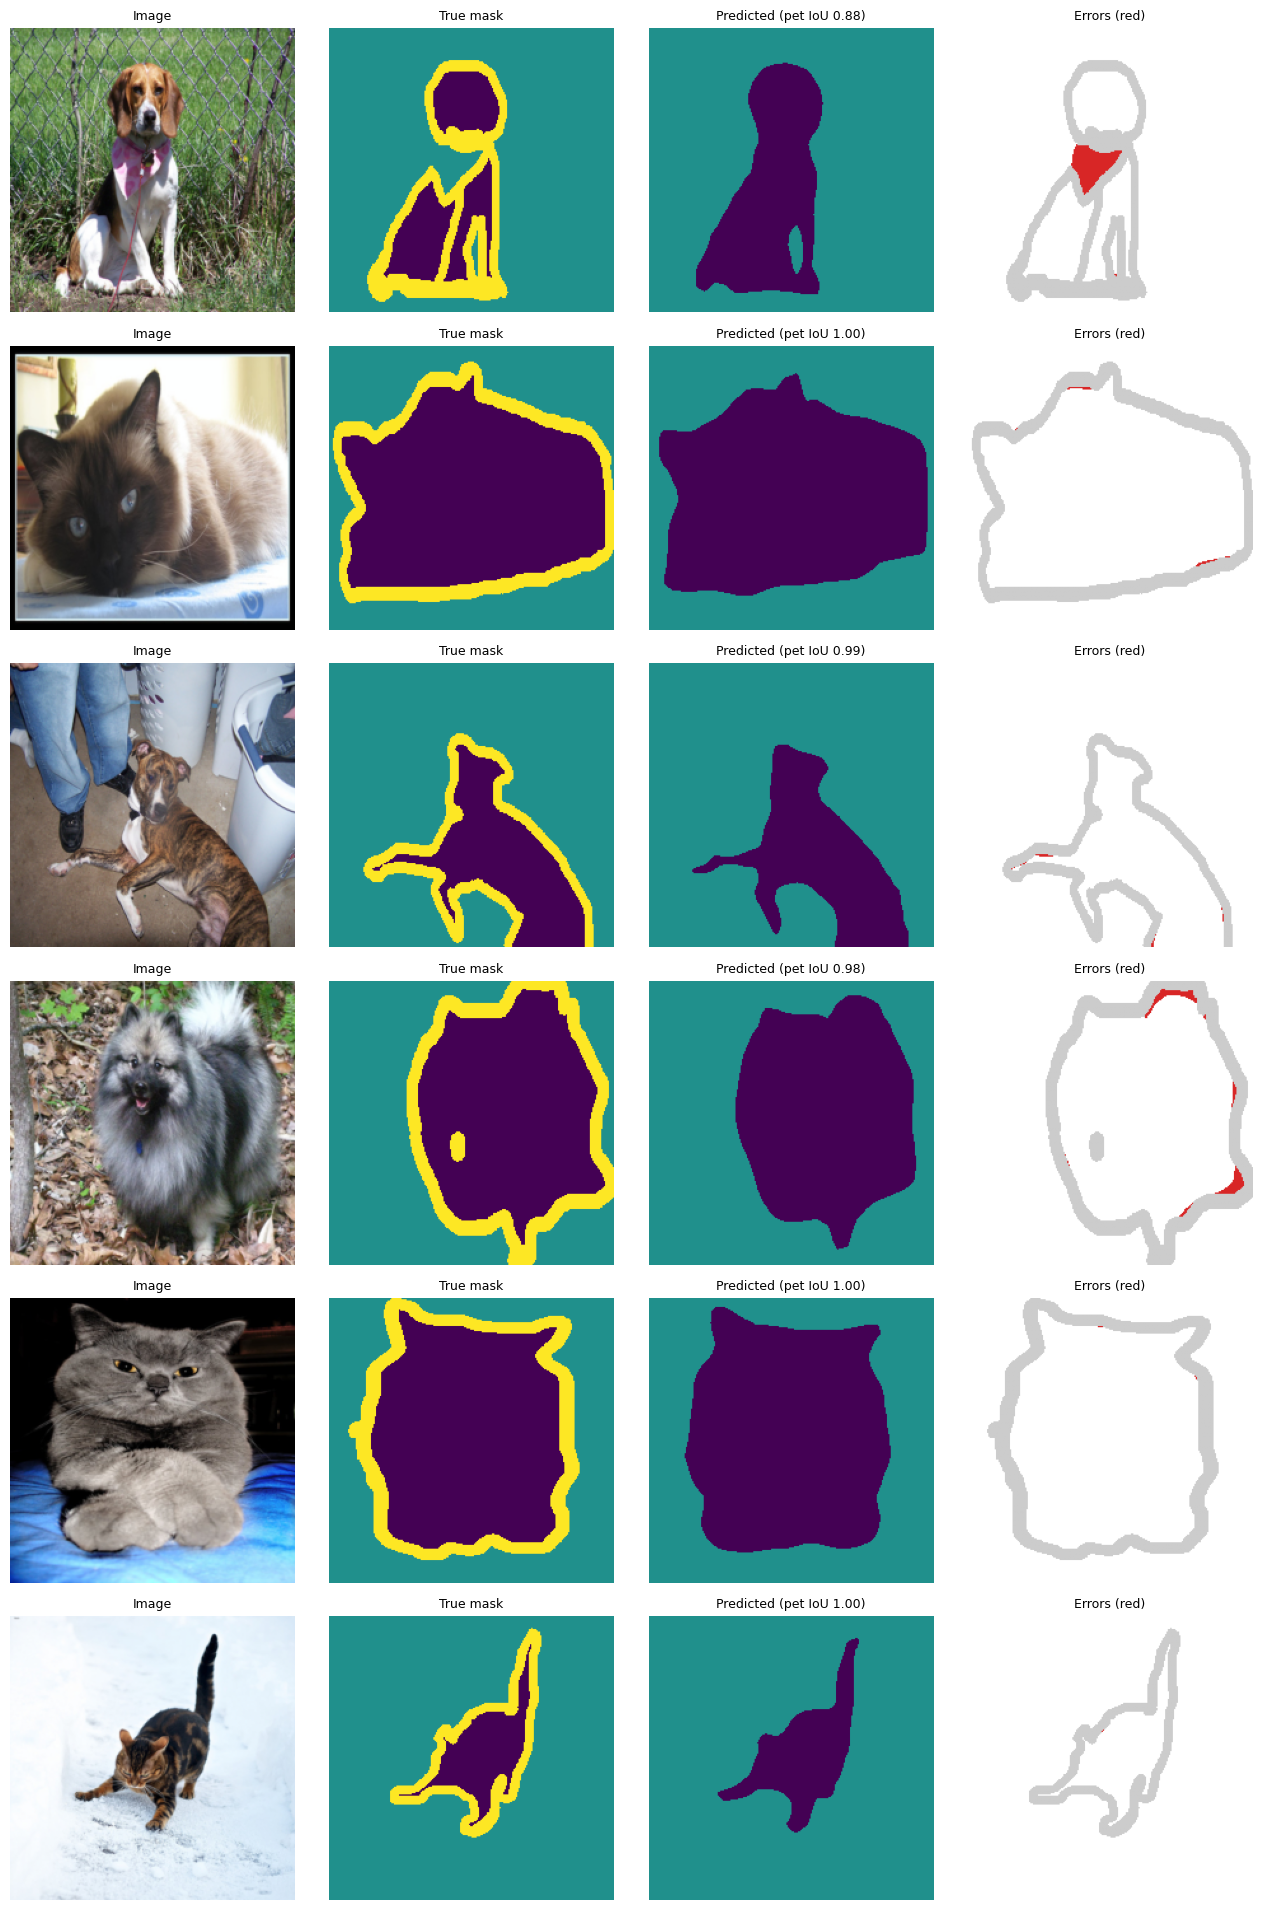

In [19]:


N_SHOW = 6      # how many validation images to display
WORST = False   # True: show the images the model does worst on instead of random ones

def predict(images):
    with torch.no_grad():
        return seg_model(images.to(device))["out"].argmax(dim=1).cpu()


def pet_iou(pred, true):
    """IoU of the pet class (0) for a single image, ignoring boundary pixels."""
    valid = true != BOUNDARY_IGNORE_INDEX
    p, t = (pred == 0) & valid, (true == 0) & valid
    return ((p & t).sum() / ((p | t).sum() + 1e-6)).item()


if WORST:
    # one extra pass over the whole validation set to score every image
    scores = []
    for images, masks in seg_val_loader:
        preds = predict(images)
        scores += [pet_iou(p, m) for p, m in zip(preds, masks)]
    indices = np.argsort(scores)[:N_SHOW].tolist()
else:
    indices = random.sample(range(len(seg_val_dataset)), N_SHOW)

samples = [seg_val_dataset[i] for i in indices]
images = torch.stack([s[0] for s in samples])
masks = torch.stack([s[1] for s in samples])
preds = predict(images)

fig, axes = plt.subplots(N_SHOW, 4, figsize=(13, 3.2 * N_SHOW))
for row, (img, true, pred) in enumerate(zip(images, masks, preds)):
    true_np, pred_np = true.numpy(), pred.numpy()

    # error map: white = correct, red = wrong, grey = ignored boundary pixels
    err = np.ones((*true_np.shape, 3))
    err[true_np == BOUNDARY_IGNORE_INDEX] = (0.8, 0.8, 0.8)
    err[(pred_np != true_np) & (true_np != BOUNDARY_IGNORE_INDEX)] = (0.85, 0.15, 0.15)

    panels = [
        (denormalize(img), "Image", None),
        (true_np, "True mask", "viridis"),
        (pred_np, f"Predicted (pet IoU {pet_iou(pred, true):.2f})", "viridis"),
        (err, "Errors (red)", None),
    ]
    for col, (data, title, cmap) in enumerate(panels):
        ax = axes[row, col]
        ax.imshow(data, cmap=cmap, vmin=0 if cmap else None, vmax=2 if cmap else None)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# Save classifier or segmentation model checkpoint
torch.save({
    'model_state_dict': model.state_dict(),
    'class_names': class_names,
    'num_classes': num_classes,
}, MODEL_PATH)